# Assignment 3
### Clarence Ballensky
Facial Expression Classification using PyTorch

## Imports

In [1]:
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torch import nn
import torchvision.models as models
import torch.optim as optim
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import os
import copy
from torchvision.transforms import v2
import matplotlib.pyplot as plt

Adding a SEED allows me to re-run the code and still get the same results. This is good for reproducability and for monitoring for improvements while tweaking the model.

In [2]:
SEED = 42
torch.manual_seed(SEED)

split_gen = torch.Generator().manual_seed(42)

## Load and Process the Data

Creating dataframes for the training data and training targets.

In [3]:
train_df = pd.read_csv("data/train_data.csv", header=None)
train_target_df = pd.read_csv("data/train_target.csv", header=None)

Investigating the training target dataframe to determine the spread of target values, where 0 corresponds to angry, 1 corresponds to happy, and 2 corresponds to neutral. These numbers reveal that the classes are imbalanced.

In [4]:
train_target_df.value_counts()

0
1    7215
2    4965
0    3995
Name: count, dtype: int64

Converting the dataframes into a dataset.

In [5]:
IMG_SIZE = 96
resize = v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True)  # one shared resizer, works on single images and batches

class CSVDataset(Dataset):
    def __init__(self, X_array, y_array, transform=None):
        self.data = X_array.astype("float32")
        self.targets = y_array.astype("int64")
        self.transform = transform
        
    def __len__(self):
        return len(self.data)
        
    def __getitem__(self, idx):
        image = torch.from_numpy(self.data[idx]).view(1, 48, 48) / 255.0   # divide by 255 (the number of pixel values) to scale down the image
        if self.transform is not None:
            image = self.transform(image) # random augmentation applied every time the image is loaded, augmentation runs at 48x48 (cheaper), before the resize
        image = resize(image)  # upscale after augmentation, for both train and validation images
        target = torch.tensor(self.targets[idx], dtype=torch.long)
        return image, torch.tensor(self.targets[idx])

Splitting the dataset into a test dataset and a validaton dataset. I am using train_test_split() so that I can stratify the data to account for the class imbalance. If this is not handled in the data processing stage, the ML model will realize it can achieve low loss and accuracy by simply guessing the majority class most of the time. 

In [6]:
# extract raw features from the dataframes
X_raw = train_df.values.astype("float32")
y_raw = train_target_df.values.astype("int64").squeeze()

# perform a statified split
X_train, X_val, y_train, y_val = train_test_split(
    X_raw, y_raw,
    test_size = 0.2,
    stratify=y_raw, # ensures identical proportions of classes in the train and validation sets
    random_state=42
)

train_transforms = v2.Compose([  # random augmentations for the training images
    v2.RandomHorizontalFlip(p=0.5),                                        # mirror half the faces
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),   # small rotation, shift and zoom
])

train_ds = CSVDataset(X_train, y_train, transform=train_transforms)
val_ds = CSVDataset(X_val, y_val)

Wrapping the datasets in dataloaders.

In [7]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False) 

## Classification

Setting the device to be "cpu".(My laptop only has a cpu, unfortunately.)

In [8]:
device = "cpu"
print(f"Using {device} device")
torch.set_num_threads(os.cpu_count()) # use all available cpu threads

Using cpu device


Loading the model. 
I will be finetuning a model from the [real competition](https://www.kaggle.com/competitions/challenges-in-representation-learning-facial-expression-recognition-challenge/overview). The model can be found [here](https://www.kaggle.com/models/ziadnasser2/best-model-without-least-3-classes/pyTorch/default).

<details>
<summary>I loaded the model and then looked at the output of this code to determine the model architecture: ResNet-50 modified for single-channel (grayscale) images instead of standard 3-channel RGB images.</summary>

    
```python

for key, value in state_dict.items():
    if 'weight' in key:
        print(f"Layer: {key} -> Shape: {list(value.shape)}")
```
</details>

Removing a custom prefix from the model.

In [9]:
model = models.resnet50()
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)

state_dict = torch.load("base_model.pth", map_location="cpu")
state_dict = {k.replace("backbone.embedding_model.", ""): v for k, v in state_dict.items()}

print(list(state_dict.keys())[:3]) 
for k in ["features.0.weight", "embedding.weight", "classifier.weight"]:
    print(k, tuple(state_dict[k].shape))

stage = {"0": "conv1", "1": "bn1", "4": "layer1", "5": "layer2", "6": "layer3", "7": "layer4"}
remapped = {}
for k, v in state_dict.items():
    if k.startswith("features."):
        _, idx, rest = k.split(".", 2)
        remapped[f"{stage[idx]}.{rest}"] = v

missing, unexpected = model.load_state_dict(remapped, strict=False)
print("MISSING   :", missing)       # should be ['fc.weight', 'fc.bias']
print("UNEXPECTED:", unexpected)    # should be []

model.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(2048, 3)) # dropout before the classifier to fight overfitting

['features.0.weight', 'features.1.weight', 'features.1.bias']
features.0.weight (64, 1, 7, 7)
embedding.weight (512, 2048)
classifier.weight (4, 512)
MISSING   : ['fc.weight', 'fc.bias']
UNEXPECTED: []


Setting the criterion and optimizer.

In [10]:
# CrossEntropyLoss() uses the Softmax function, good for multi-class classification
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) # label_smoothing helps mitigate overfitting

# AdamW() is the industry standard for vision models
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)

## Training Loop and Evaluation

Creating a method to evaluate model performance.

In [11]:
def eval(model, loader, device):
    model.eval() # set model to evaluation mode
    correct, total, loss_sum = 0, 0, 0.0
    all_preds, all_labels = [], []
    
    with torch.no_grad(): # gradient tracking is not needed for evaluation
        for X, y in loader:
            
            X, y = X.to(device), y.to(device)
            
            logits = model(X)
            
            # criterion(logits, y): avg loss from this batch (one-item tensor); .item() makes it the tensor a number
            # * len(y) to convert avg loss from this batch to total loss from this batch
            loss_sum += criterion(logits, y).item() * len(y)
            
            preds = torch.argmax(logits, dim=1) # multi-class classification: pick the index of the highest logit
            correct += (preds == y).sum().item() # count the number of predictions that match the true value
            total += len(y)

            all_preds.append(preds.cpu())
            all_labels.append(y.cpu())
            
        all_preds = torch.cat(all_preds).numpy()
        all_labels = torch.cat(all_labels).numpy()

        metrics = {
            "loss": loss_sum / total,
            "accuracy": correct / total,
            # For each metric, average="macro" takes the unweighted average of the values associated with each class (angry, neutral, happy)
            "precision": precision_score(all_labels, all_preds, average="macro", zero_division=0),
            "recall": recall_score(all_labels, all_preds, average="macro", zero_division=0),
            "f1": f1_score(all_labels, all_preds, average="macro", zero_division=0)
        }
        
        return metrics

Adding flip test-time augmentation. This averages the model's output on an image and its mirror for each metric.


In [12]:
def predict_logits_tta(model, X_tensor, device, bs=256): 
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X_tensor), bs):
            xb = X_tensor[i:i + bs].to(device)
            logits = (model(xb) + model(xb.flip(3))) / 2  # flip(3) mirrors left-right
            out.append(logits.cpu())
    return torch.cat(out)

Freezing early layers, only training the final layer. This will speed up training immensely and prevent over-fitting.

In [13]:
# turn off gradient tracking for all parameters
for param in model.parameters():
    param.requires_grad = False


# unfreeze only the later layers
for param in model.layer3.parameters():
    param.requires_grad = True

for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True


# tell the optimizer to only look at the unfrozen layers
optimizer = torch.optim.AdamW(
    [
        {"params": model.layer3.parameters(), "lr": 3e-5}, # smallest steps for the earliest layer
        {"params": model.layer4.parameters(), "lr": 7e-5},
        {"params": model.fc.parameters(),     "lr": 1e-4},  
    ],
    weight_decay=2e-2
)

epochs = 20

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) # decay learning rate to ~0 so the final epochs are stable

frozen_blocks = [model.conv1, model.bn1, model.layer1, model.layer2]

Training loop.

In [14]:
print(f"Validation set metrics:\n")

# track the best performing model weights
best_accuracy = 0.0
best_model_weights = None

for epoch in range(epochs):
    model.train() # set model to training mode

    # do not train frozen blocks
    for block in frozen_blocks: 
        block.eval()
    
    for X, y in train_loader: # train_loader is an instance of DataLoader, yields randomized batch of labels and features
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad() # reset gradients of all model parameters before creating new ones

        # forward pass
        loss = criterion(model(X), y)

        # backward pass
        loss.backward()
        optimizer.step()

    scheduler.step() # advance the learning rate schedule

    # evaluate each epoch to catch overfitting early 
    m = eval(model, val_loader, device)

    print(f"Epoch {epoch+1}: Loss {m['loss']:.4f}, Accuracy {m['accuracy']:.3f}, "
          f"Precision {m['precision']:.3f}, Recall {m['recall']:.3f}, f1 {m['f1']:.3f}")

    if m["accuracy"] > best_accuracy:
        best_accuracy = m["accuracy"]
        # copy the best weights found so far
        best_model_weights = copy.deepcopy(model.state_dict())
        print(f"--> New best model saved! (Best Accuracy: {best_accuracy:.3f})")

# load the best model before making final predictions
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("\nTraining complete. Best model weights restored successfully.")

Validation set metrics:

Epoch 1: Loss 0.6458, Accuracy 0.794, Precision 0.777, Recall 0.764, f1 0.769
--> New best model saved! (Best Accuracy: 0.794)
Epoch 2: Loss 0.6304, Accuracy 0.797, Precision 0.793, Recall 0.760, f1 0.766
--> New best model saved! (Best Accuracy: 0.797)
Epoch 3: Loss 0.6127, Accuracy 0.814, Precision 0.798, Recall 0.792, f1 0.794
--> New best model saved! (Best Accuracy: 0.814)
Epoch 4: Loss 0.5983, Accuracy 0.822, Precision 0.806, Recall 0.799, f1 0.802
--> New best model saved! (Best Accuracy: 0.822)
Epoch 5: Loss 0.5890, Accuracy 0.825, Precision 0.810, Recall 0.805, f1 0.806
--> New best model saved! (Best Accuracy: 0.825)
Epoch 6: Loss 0.5874, Accuracy 0.826, Precision 0.812, Recall 0.806, f1 0.808
--> New best model saved! (Best Accuracy: 0.826)
Epoch 7: Loss 0.5834, Accuracy 0.829, Precision 0.815, Recall 0.811, f1 0.811
--> New best model saved! (Best Accuracy: 0.829)
Epoch 8: Loss 0.5820, Accuracy 0.828, Precision 0.814, Recall 0.806, f1 0.809
Epoch 9:

Saving the model.

In [15]:
torch.save(model.state_dict(), "model_20epoch.pth")

Creating submission file using the test data.

In [16]:
# load the test data 
test_df = pd.read_csv("data/test_data.csv", header=None)
X_test = test_df.values.astype("float32")

X_test_t = resize(torch.from_numpy(X_test).view(-1, 1, 48, 48) / 255.0)

test_logits = predict_logits_tta(model, X_test_t, device)
preds = test_logits.argmax(1).numpy()  # pick the class with the highest averaged logit

LABEL_COLUMN = "Category"
submission = pd.DataFrame({"Id": np.arange(len(preds)), LABEL_COLUMN: preds})
submission.to_csv("submission_full.csv", index=False)  # index=False so no extra column is written
print(submission.head(), "\n", submission[LABEL_COLUMN].value_counts())

   Id  Category
0   0         0
1   1         0
2   2         0
3   3         1
4   4         2 
 Category
1    1802
2    1252
0     911
Name: count, dtype: int64


Charting evaluation metrics.

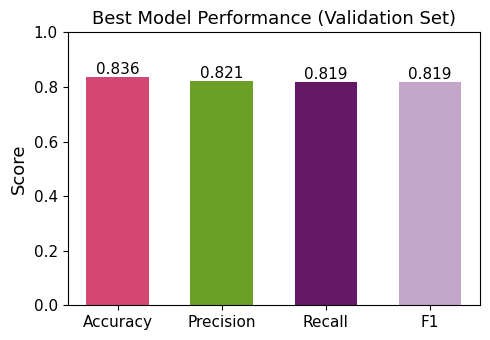

In [17]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]
scores = [m["accuracy"], m["precision"], m["recall"], m["f1"]]

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(metrics, scores, width=0.6,
       color=["#D54773", "#6B9F25", "#641866", "#C4A6CA"])
ax.bar_label(ax.containers[0], fmt="%.3f", fontsize=11)

ax.set_ylabel("Score", fontsize=13)
ax.set_ylim(0, 1)
ax.set_title("Best Model Performance (Validation Set)", fontsize=13)  
ax.tick_params(axis="both", labelsize=11) 
plt.tight_layout()
plt.show()